In [ ]:
%load_ext autoreload
%autoreload 2
from notebook import *
# if get something about NUMEXPR_MAX_THREADS being set incorrectly, don't worry.  It's not a problem.

<div class="namebox">    
Double Click to edit and enter your

1.  Name
2.  Student ID
3.  @ucr.edu email address
    
</div>

<div style=" font-size: 300% !important;
    margin-top: 1.5em;
    margin-bottom: 10px;
    font-weight: bold;
    line-height: 1.0;
    text-align:center;">
Assignment 3: Improve Code Performance with Our Knowledge on Memory Subsystems!
</div>

In this assignment, you'll learn about the concepts of:

1. Sources of cache misses
2. Memory alignment
3. Cache-aware optimizations (Useful for Programming Assignment 1)

Check the course schedule for due date(s).

We need to thank [Dr. Steven Swanson](https://cseweb.ucsd.edu/~swanson/) as a significant part of the assignment is orginated from Dr. Swanson's teaching materials.

# FAQ and Updates

* There are no updates, yet.

# About Assignments/Labs In This Class



_This section is the same in all the assignments.  It's repeated here for your reference._

CS203 assignments are designed in a way to **learn by doing**.  This means you _must_ **do**.  WE have built these assignments as Jupyter notebooks so that the "doing" is as easy and seamless as possible. (Largely contributed by Steven Swanson at UCSD https://cseweb.ucr.edu/~swanson/)

In this assignment, what you'll do is answer questions about how a program will run and then compare what really happened to your predictions.  Engaging with this process is how you'll learn.  The questions that the assignment asks are there for several purposes:

1.  To draw your attention to specific aspects of an experiment or of some results.
2.  To push you to engage with the material more deeply by thinking about it.
3.  To make you commit to a prediction so you can wonder why your prediction was wrong or be proud that you got it right.
4.  To provide some practice with skills/concepts you're learning in this course.
5.  To test your knowledge about what you've learned.

You'll notice that there are three kinds of questions: "Correctness", "Challenging", and "Completeness". 

<div class="alert alert-block alert-success">

**Correctness**: You need to answer these questions with correct answers and supporting evidences (e.g., explainations, formula, equations) to get credits.

</div>
<div class="alert alert-block alert-warning">

**Challenging**: These questions are also graded by correctness, but they account for 20% of the grades in this assignment in total as they're more difficult or repetitive. 

</div>

<div class="alert alert-block alert-info">

**Completeness**: You need to complete all these questions to receive credits. We do not grade these questions on correctness, but you need to show significant efforts regarding your process of deriving the answers.

</div>

In other words, 
- If you want to get full credits, you need to answer all **Correctness** and **Challenging** correctly, and finish all **Completeness** questions.
- If you want to get 80% of the credits, you still need to answer all **Correctness** correctly and finish **Completeness** questions.

Many of our questions must answer based on prior experimental results. If you skip any prior cell, you may get a parsing error in questions from our autograder.

Some of the "Completeness" problems include a solution that will be hidden until you click the triangle below the question.  To get the most from them, try them on your own first.

Many of the "Completeness" questions ask you to make predictions about the outcome of an experiment and write down those predictions.  To maximize your learning, think carefully about your prediction and commit to it.  **You will never be penalized for making an incorrect prediction.**

You are free to discuss questions with your classmatesm, but you must complete all questions on your own.

If you have questions about any kind of question, please ask during office hours or during class.


## How To Succeed On the assignments

Here are some simple tips that will help you do well on this assignment:

1.  Read/skim through the entire assignment and review the lecture/textbook. 
2.  Start early.  Getting answers on discord can take time.  So think through the questions (and your questions about them) carefully.
    1. Go through the assignment once (several days before the deadline), do the parts that are easy/make sense
    2. Ask questions/think about the rest
    3. Come back and do the rest.
3.  Start early.  The gradescope server/cluster can be busy and slow near deadlines.  **"The gradescope server/cluster was slow the night of the deadline"** is **not an excuse** for not getting the assignment done and it is not justification for asking for an extension.
4.  Follow the guidelines below for asking answerable questions on discord.

You may think to yourself: "If I start early enough to account for all that, I'd have to start right after the assignment was announced!"  Good thought!

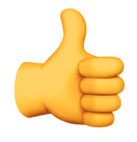

<div class="alert alert-block alert-danger">

**The Cluster Will Get Slow** and our machines will get crowded and slow _before every deadline_.  This is completely predictable.  The cluster can also get crowded due to deadlines in other courses.  You need to start early so you can avoid/work around these slowdowns.  Unless there's some kind of complete outage, we will not grant extensions because the servers are crowded.
    
</div>

## Getting Help

You might run into trouble while doing this assignment.  Here's how to get help:

1.  Re-read the instructions and make sure you've followed them.
2.  Try saving and reloading the notebook.
3.  If you get a `FileNotFoundError` make sure you've run all the code cells above your current point in the assignment.
4.  If you get a message like `render_code is not defined`, please make sure you've run all the code cells above your current point in the assignment.
5.  If you get an exception or stack dump, check that you didn't accidentally modify the contents of one of the python cells.
6.  If all else fails, post a question to discord or visit an office hour.

## Posting Answerable Questions on Piazza

If you want useful answers on piazza, you need to provide information that is specific enough for us to provide a useful answer.  Here's what we need:

1.  Which part of which assignment are you working on (use the section numbers)?
2.  Which problem (copy and paste the _text_ of the question along with the number).

If it's question about instructions:

1.  Try to be as specific as you can about what is confusing or what you don't understand (e.g., "I'm not sure if I should do _X_ or _Y_.")

If it's a question about an error while running code, then we need:

1.  If you've committed anything, your github repo url.
2.  If you've submitted a job with `cs203` you _must_ provide the job id.  With the id, we can figure out just about anything about your job.  Without it, we know nothing.
3.  The _entire_ output you received.  There's no limit on how long an discord post can be.  Give us all the information, not just the last few lines.  We like to scroll!

For all of the above **paste the text** into the discord question.  Please **do not provide screen captures**.  The course staff refuses to type in job ids found in screen shots.


<div class="alert alert-block alert-danger">

**We Can't Answer Unanswerable Questions** If you don't follow these guidelines (especially about the github repo and the job id), we will probably not be able to answer your question on discord.  We will archive it and ask you to re-post your question with the information we need.
    
**We Can't Answer Questions 24/7** Please respect the fact that the TAs/instructors are real human beings and we have limitations and other job commitments. Please give people at least 24 hours to answer a question. In other words, you should not expect a question 24 hours before the deadline to be answered in time.
    
</div>

## Keeping Your assignment Up-to-Date

Occasionally, there will be changes made to the base repository after the
lab is released.  This may include bug fixes and updates to this document.  We'll post on discord when an update is available.

In those cases, you can use the following commands to pull the changes from upstream and merge them into your code.  You'll need to do this at a shell.  It won't work properly in the notebook.  

**Important: Save your notebook in the browser first.**


```
cd <your directory for this assignment>git remote add upstream $(cat .starter_repo)  # You need to do this once each time you checkout a new assignment. It will fail 
                                              # harmlessly if you run it more than once.
cp assignment.ipynb assignment.backup.ipynb                 # Backup your work.
git commit -am "My progress so far."          # commit your work.
git pull upstream main --allow-unrelated-histories -X theirs # pull the updates
```

Or you can use the script we provide:

In [ ]:
# Important!!! Be sure to click save to preseve your progress before using the following script
! ./fix-repo
! ./pull-updates
# Then reload this page in your browser!!!

**Important: Then, reload this page in your browser.**

<div class="alert alert-block alert-danger">

**The Cluster Will Get Slow** and our machines will get crowded and slow _before every deadline_.  This is completely predictable.  The cluster can also get crowded due to deadlines in other courses.  You need to start early so you can avoid/work around these slowdowns.  Unless there's some kind of complete outage, we will not grant extensions because the servers are crowded.
    
</div>

## How To Use This Document

You will use Jupyter Notebook to complete this assignment/lab.  You should be able to do much of this assignment/lab without leaving Jupyter Notebook.  The main exception will be some of the programming chanllenges.  The instructions will make it clear when you should use the terminal.

### Running Code

Jupyter Notebooks are made up of "cells".  Some have Markdown-formatted text in them (like this one).  Some have Python code (like the one below).

For code cells, you press `shift-return` to execute the code.  Try it below:

In [ ]:
print("I'm in python")

Code cells can also execute shell commands using the `!` operator.  Try it below:

In [ ]:
!echo "I'm in a shell"

### Telling What The Notebook is Doing

The notebook will only run one cell at a time, so if you press `shift-return` several times, the cells will wait for one another.  You can tell that a cell is waiting if it there's a `*` in the `[]` to the left the cell:

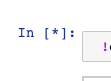


You'll can also tell _where_ the notebook is executing by looking at the table of contents on the left.  The section with the currently-executing cell will be red:

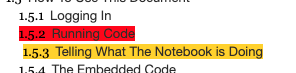

### What to Do Jupyter Notebook It Gets Stuck

First, check if it's actually stuck: Some of the cells take a while, but they will usually provide some visual sign of progress.  If _nothing_ is happening for more than 10 seconds, it's probably stuck.

To get it unstuck, you stop execution of the current cell with the "interrupt button":

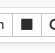

You can also restart the underlying python instance (i.e., the confusingly-named "kernel" which is not the same thing as the operating system kernel) with the restart button:

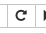

Once you do this, all the variables defined by earlier cells are gone, so you may get some errors.  You may need to re-run the cells in the current section to get things to work again.

You can also try reloading the web page.  That will leave Python kernel intact, but it can help with some problems.

### The Embedded Code

The code embedded in the assignment falls into two categories:

1.  Code you need to edit and understand.
2.  Code that you do not need to edit or understand -- it's just there to display something for you.

For code in the first category, the assignment will make it clear that you need to study, modify, and/or run the code.  If we don't explicitly ask you to do something, you don't need to.

Most of the code in the second category is for drawing graphs.  You can just run it with shift-return to the see the results.  If you are curious, it's mostly written with `Pandas` and `matplotlib`. The code is all in `notebook.py`.   These cells should be un-editable.  However, if you want to experiment with them, you can copy _the contents_ of the cell into a new cell and do whatever you want (If you copy the cell, the copy will also be uneditable).

<div class="alert alert-block alert-warning">

**Most Cells are Immutable** Many of the cells of this notebook are uneditable. The only ones you should edit are some of the code cells and the text cells with questions in them.
</div>

### Answering Questions

Throughout this document, you'll see some questions (like the one below).  You can double click on them to edit them and fill in your answer.  Try not to mess up the formatting (so it's easy for us to grade), but at least make sure your answer shows up clearly.  When you are done editing, you can `shift-return` to make it pretty again.

A few tips, pointers, and caveats for answering questions:

1. The answers are all in [github-flavored markdown](https://guides.github.com/features/mastering-markdown/) with some html sprinkled in.  Leave the html alone.
2. Many answers require you to fill in a table, and many of the `|` characters will be missing.  You'll need to add them back.
3. The HTML needs to start at the beginning of a line.  If there are spaces before a tag, it won't render properly.  If you accidentally add white space at the beginning of a line with an html tag on it, you'll need to fix it.
4. Text answers also need to start at the beginning of a line, otherwise they will be rendered as code.
5. Press `shift-return` or `option-return` to render the cell and make sure it looks good.
6. There needs to be a blank line between html tags and markdown.  Otherwise, the markdown formatting will not appear correctly.
7. Many of our questions must answer based on prior experimental results. If you skip any prior cell, you may get a parsing error in questions from our autograder.


You'll notice that there are three kinds of questions: "Correctness", "Completeness", and "Challenging". 

- Correctness: You need to answer these questions with correct answers and supporting evidences (e.g., explainations, formula, equations) to get credits.

- Challenging: These questions are also graded by correctness, but they account for 20% of the grades in this assignment in total as they're more difficult or repetitive.

- Completeness: You need to complete all these questions to receive credits. We do not grade these questions on correctness, but you need to show significant efforts regarding your process of deriving the answers.

### Regarding Our Autograder

In this class, we introduced the autograder on Gradescope. However, please be aware the purpose of autograder is to replace the TA and potentially give you early feedback of your assignment if you submit early. The autograder is not intended to give you a short-cut of receiving full credits in assignments. Here are some disclaimers about our autograders and tips regarding how to compose good answers.

1. Please provide **detailed** explainations and processes, not just the answer. Please consider the autograder as a real TA/professor. We want to see how you get an answer, not just the answer itself.
2. Please use the **precise** terminology/wording as we teach/use in the class/assignment. Being precise is very important in communications and collaborative environments.  
3. Please use the **exact** numbers from your measurements and please don't round your computation result if appropriate. For many questions that ask you to evaluate the answers using the real performance counter results, the autograder will parse some prior cells and grade your answers based on the experimental result. The autograder cannot correctly identify if you really use those results if you round your numbers from the output of the performance numbers.
4. Please have the **right expectations** of the response from the autograder. As a normal TA/instructor, the autograder's response is not to tell you how to get a correct answer, but only provide a general feedback regarding where/what you might get wrong. If you really need personalized help or clarification regarding the concept of questions, please consider visiting an office hour or asking on discord at an appropriate timeslot.
5. Please be aware that autograder are already **more relaxed** than the TAs/instructor. The autograder are more flexible than the TAs/instructor since we cannot have too complex heuristics in the autograder. That also means that you have to pay attention to the released solution. Getting full credits from the autograder does not mean you will get the same when the TAs/instructor grade the same question.

# The Three C's

Recall from lecture (or review the slides) that we can classify cache misses into types (known as "The Thee C's"):

1.  **Compulsory**: These misses occur because the processor has not accessed this cache line before.

2.  **Capacity**: These occur because the program is accessing more memory than the cache can hold (i.e., it's working set is bigger than the cache).

3.  **Conflict**: These occur because a given cache line of memory can only live in one of the associative sets of the cache.

## Capacity and Compulsory Misses

In this assignment, we will start our investigation of spatial locality, temporal locality, and working sets illustrated compulsory and capacity misses.

Let's reuse the simple test program that accesses a 1-dimensional tensor at different "strides". Remeber, the "stride" of a sequence of accesses is just the distance between consecutive accesses.  So, "stride 1" means accessing each element, and "stride 2" means accessing every other element.  The outer loop ensures ensures that the total number of accesses the loop perform remains the same, regardless of stride size).

Run the code below, and then answer these question:

In [ ]:
t = fiddle("stride_2.cpp", function="stride", name="spatial", opt="-O1",
code=r"""

#include"function_map.hpp"
#include<cstdint>



extern "C"
uint64_t* stride_2(uint64_t * data, uint64_t size, uint64_t arg1) {
    
    uint64_t sum = 0;
    for(uint i = 0; i < arg1; i++) {
        for(uint x = 0; x < size; x+=arg1) {
            sum += data[x];
        }
    }
    data[0] =sum;
    return data;
}

FUNCTION(one_array_1arg, stride_2);
""")

!make build/stride_2.so C_OPTS='-mno-avx -O1' fiddle.exe
!cs203 run './fiddle.exe -l build/stride_2.so -M 3800 -f stride_2 -s 1024 16384 -a 1 -i 1 -o temporal.csv'
df = render_csv("temporal.csv", average_by = "size",columns=["arg1", "IC", "CPI", "CT", "ET", "L1_dcache_miss_rate","L1_dcache_misses","L1_dcache_accesses"])
display_mono(df)
plotPE(df=df, lines=True, what=[ ('size', 'CPI'), ('size', 'L1_dcache_miss_rate')])

<div class="alert alert-block alert-success">

### Question 1 (Correctness)
    
What's the major types of misses when we run the above cell with `arg1 ==1` but with `size == 1024` and `size == 16384`. 


</div>

<div class="alert alert-block alert-success">
<div class="answer">
Answer:

**What's the major type of 'stride()' in Question 1 when `size == 1024`? You should clearly going through all possiblities to explain why it's indeed the type of misses you answered. **

**What's the major type of 'stride()' in Question 1 when `size == 16384`? You should clearly going through all possiblities to explain why it's indeed the type of misses you answered.**

</div>
</div>

In [ ]:
t = fiddle("stride_2.cpp", function="stride", name="spatial", opt="-O1",
code=r"""

#include"function_map.hpp"
#include<cstdint>



extern "C"
uint64_t* stride_2(uint64_t * data, uint64_t size, uint64_t arg1) {
    
    uint64_t sum = 0;
    for(uint i = 0; i < arg1; i++) {
        for(uint x = 0; x < size; x+=arg1) {
            sum += data[x];
        }
    }
    data[0] =sum;
    return data;
}

FUNCTION(one_array_1arg, stride_2);
""")

!make build/stride_2.so C_OPTS='-mno-avx -O1' fiddle.exe
!cs203 run './fiddle.exe -l build/stride_2.so -M 3800 -f stride_2 -s 1024 2048 4096 8192 16384 32768 65536 -a 4 -i 1 -o temporal_2.csv'
df = render_csv("temporal_2.csv", average_by = "size",columns=["arg1", "IC", "CPI", "CT", "ET", "L1_dcache_miss_rate","L1_dcache_misses","L1_dcache_accesses"])
display_mono(df)
plotPE(df=df, lines=True, what=[ ('size', 'CPI'), ('size', 'L1_dcache_miss_rate')])

<div class="alert alert-block alert-success">

### Question 2 (Correctness)
    
What's the major types of misses when we run the above cell with `arg1 ==4` but `size == 1024` and `size == 16384`. 


</div>

<div class="alert alert-block alert-success">
<div class="answer">
Answer:

**What's the major type of 'stride()' in Question 2 when `size == 1024`? You should clearly going through all possiblities to explain why it's indeed the type of misses you answered.**

**What's the major type of 'stride()' in Question 2 when `size == 16384`? You should clearly going through all possiblities to explain why it's indeed the type of misses you answered.**

</div>
</div>

<div class="alert alert-block alert-danger">

**Compulsory** The misses that occur in the first time through the inner loop of `stride()` are all compulsory misses.
</div>

<div class="alert alert-block alert-danger">

**Capacity** In the same experiment, we saw that when the number of cachelines accessed exceeds the number of cache lines in the cache, we get many misses.  These are all capacity misses:
   
</div>

### An alternative way of accessing memory

In addition to conventional load and store instructions, modern processors provide architecture-specific memory access instructions using their vector processors. Though they are originally designed for loading/storing a vector once, we can still use them in general, non-vectorized arithmetics. 
Intel intrinsics (such as the family declared under <immintrin.h>) are specialized compiler-provided functions that map directly to low-level hardware vector instructions. Instead of relying on the compiler’s automatic vectorization algorithms to detect opportunities for parallelism, intrinsics let developers explicitly orchestrate wide SIMD (Single Instruction, Multiple Data) operations directly from high-level code.

Please run the following cell and observe how these vector memory instructions changes the behavior of our code.

In [ ]:
t = fiddle("stride_3.cpp", function="stride", name="spatial", opt="-O1",
code=r"""

#include"function_map.hpp"
#include<cstdint>
#include <immintrin.h>



extern "C"
uint64_t* stride_3(uint64_t * data, uint64_t size, uint64_t arg1) {
    
    __m256i vsum = _mm256_setzero_si256();
    uint64_t x = 0;

    // Process 4 x 64-bit integers per AVX register
    for (; x + 4 <= size; x += 4) {
        __m256i val = _mm256_loadu_si256((const __m256i*)&data[x]);
        vsum = _mm256_add_epi64(vsum, val);
    }

    // Horizontal sum of the 256-bit register
    uint64_t buffer[4];
    _mm256_storeu_si256((__m256i*)buffer, vsum);
    uint64_t sum = buffer[0] + buffer[1] + buffer[2] + buffer[3];

    // Handle remainder elements
    for (; x < size; x++) {
        sum += data[x];
    }

    data[0] = sum * arg1;
    return data;
}

FUNCTION(one_array_1arg, stride_3);
""")

!make build/stride_3.so C_OPTS='-mavx2 -O1' fiddle.exe
!cs203 run './fiddle.exe -l build/stride_3.so -M 3800 -f stride_3 -s 1024 16384 -a 1 -i 1 -o temporal_3.csv'
df = render_csv("temporal_3.csv", average_by = "size",columns=["arg1", "IC", "CPI", "CT", "ET", "L1_dcache_miss_rate","L1_dcache_misses","L1_dcache_accesses"])
display_mono(df)
plotPE(df=df, lines=True, what=[ ('size', 'CPI'), ('size', 'L1_dcache_miss_rate')])

You probably observed, the miss rate is actually very high compare against the same set of arguments we used previously. However, the performance seems to be better. Can you check the performance counter results in the table in detail and answer the following question?

<div class="alert alert-block alert-warning">

### Question 3 (Challenging)

Considering the `stride_3` function where we explicitly use AVX instructions in the code to hard code the case when `arg == 1`. Compare with the previous table on that result, the miss rate should go up now. However, it seems the performance stays the same or even better. Why the modified code has a better performance given higher miss rates?

</div>

<div class="alert alert-block alert-warning">
<div class="answer">

**You must explain the reason in good enough detail to score since this is a challenging question. You should discuss what type of misses it affects and all other factors that might lead to this result**

</div>
</div>

# Thinking in Cache Lines

One of the central issues in cache-aware programming (i.e., crafting your code to make efficient use of the memory hierarchy) is understanding "how much" memory your program (or part of it) is using and "how big" a particular data structure (e.g., an array) is, and how often your program accesses memory.  It turns out there are a surprising number of ways to measure these things and the answers can be unexpectedly surprising and non-intuitive.  Not only that, the most obvious ways to measure these characteristics are not the most useful if you're interested in fully-utilizing your memory system.

So let's take a look at three questions and see how to answer them in a cache-aware way.

## How big is my data structure?

### Primitive Types

Let's start simple:  How many bytes do each of the primitive C++ data types occupy?  Here's some code to check.  It uses C's `sizeof` operator (it's not technically a function.  Why?) that tells you how many bytes something occupies.  The types listed are all the C++ primitive types.

In [ ]:
t = fiddle("primitive_sizes.cpp", function="primitive_sizes",
code=r"""
#include<cstdint>
#include<iostream>
#include"function_map.hpp"

extern "C"
uint64_t* primitive_sizes(uint64_t * data, uint64_t size, uint64_t arg1) {
    std::cout << "\n";
    std::cout << "sizeof(char) = " << sizeof(char) << "\n";
    std::cout << "sizeof(short int) = " << sizeof(short int) << "\n";
    std::cout << "sizeof(int) = " << sizeof(int) << "\n";
    std::cout << "sizeof(long int) = " << sizeof(long int) << "\n";
    std::cout << "sizeof(long long int) = " << sizeof(long long int) << "\n";
    std::cout << "sizeof(float) = " << sizeof(float) << "\n";
    std::cout << "sizeof(double) = " << sizeof(double) << "\n";
    std::cout << "sizeof(long double) = " << sizeof(long double) << "\n";
    std::cout << "sizeof(int8_t) = " << sizeof(int8_t) << "\n";
    std::cout << "sizeof(int16_t) = " << sizeof(int16_t) << "\n";
    std::cout << "sizeof(int32_t) = " << sizeof(uint32_t) << "\n";
    std::cout << "sizeof(int64_t) = " << sizeof(int64_t) << "\n";
    std::cout << "sizeof(int64_t*) = " << sizeof(int64_t*) << "\n";
    std::cout << "sizeof(void*) = " << sizeof(void*) << "\n";
    return data;
}

FUNCTION(one_array_1arg, primitive_sizes);
""")
!make build/primitive_sizes.so C_OPTS='-O1' fiddle.exe
!cs203 run './fiddle.exe -l build/primitive_sizes.so -f primitive_sizes'

The types with a number in their names (like `uint64_t`) let you specify specific sizes (in bits) you'd like to use.  They are defined in the `cstdint` header.  The [C/C++ standard](https://en.wikipedia.org/wiki/C_data_types) doesn't give specific sizes for 'int', 'long int', etc.  Instead, it places some constraints on what possible values might be.  This is a design "bug" in the languages.  I don't know of any other modern languages that leave the bit widths of primitive types unspecified.  One reason is that it hurts portability.  The other, is that it makes cache-aware programming harder (as we shall see).

### Structs

Let's try something more complicated.  Look at the code below and answer this question.  Then, run the code:

In [ ]:
t = fiddle("struct1.cpp", function="struct_size",
code=r"""
#include<cstdint>
#include<iostream>
#include"function_map.hpp"

struct struct_1 {
    uint32_t a;
};

struct struct_2 {
    uint32_t a;
    uint32_t b;
};

struct struct_3 {
    uint32_t a;
    uint8_t b;
};

struct struct_4 {
    uint64_t a;
    uint8_t b;
};

struct struct_5 {
    uint8_t a;
    uint8_t b;
};

struct struct_6 {
    uint64_t a;
    uint8_t b;
} ;

struct struct_7 {
    uint64_t a;
    uint8_t b;
    uint8_t c;
} ;

struct struct_8 {
    uint8_t a;
    uint64_t b;
    uint8_t c;
} ;


extern "C"
uint64_t* struct_size(uint64_t * data, uint64_t size, uint64_t arg1) {
    std::cout << "\n";
    std::cout << "sizeof(struct_1) = " << sizeof(struct_1) << "\n";
    std::cout << "sizeof(struct_2) = " << sizeof(struct_2) << "\n";
    std::cout << "sizeof(struct_3) = " << sizeof(struct_3) << "\n";
    std::cout << "sizeof(struct_4) = " << sizeof(struct_4) << "\n";
    std::cout << "sizeof(struct_5) = " << sizeof(struct_5) << "\n";
    std::cout << "sizeof(struct_6) = " << sizeof(struct_6) << "\n";
    std::cout << "sizeof(struct_7) = " << sizeof(struct_7) << "\n";
    std::cout << "sizeof(struct_8) = " << sizeof(struct_8) << "\n";
    return data;
}

FUNCTION(one_array_1arg, struct_size);
""")

<div class="alert alert-block alert-success"><div class="question completeness"> 

### Question 4 (Correctness)

<div class="question-text">

Predict how many bytes of the structs below will occupy.
    
</div>
   
<div class="answer">

| struct | sizeof() |
|--------|----------|
| `struct_1` |     | 
| `struct_2` |     | 
| `struct_3` |     | 
| `struct_4` |     | 
| `struct_5` |     | 
| `struct_6` |     | 
| `struct_7` |     | 
| `struct_8` |     | 
    
</div>
</div>
</div>

<div class="alert alert-block alert-success">    
<div class="answer">

| struct | sizeof() |
|--------|----------|
| `struct_1` |     | 
| `struct_2` |     | 
| `struct_3` |     | 
| `struct_4` |     | 
| `struct_5` |     | 
| `struct_6` |     | 
| `struct_7` |     | 
| `struct_8` |     | 
    
</div>
</div>

Let's check your answers through running the cell below!

In [ ]:
!make build/struct1.so C_OPTS='-O1' fiddle.exe
!cs203 run './fiddle.exe -l ./build/struct1.so -f struct_size'

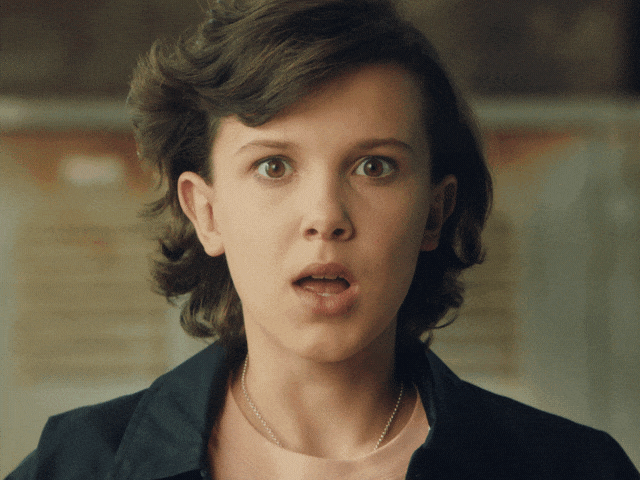

What's going on?!?!

What's going on is _data alignment_.  If a memory address, $A$, is $n$-byte aligned, then $A\mod{} n = 0$.  A particular value is "width-aligned" if it is aligned to its own size in bytes.  So, a width-aligned `uint64_t` would reside at an address that is a multiple of 8 bytes.

In most architecture, width-aligned access is faster than non-width-aligned access.  In some architectures, the ISA does not directly support non-width-aligned access (i.e., you can't load a 64-bit value from an address that is not a multiple of 8), because it requires extra hardware and complexity (e.g., if the architecture allows unaligned, multi-byte values, then a single load can access _two_ cache lines instead of one).  Instead, they require the compiler to implement these accesses with loads and shifts.

The strangeness in the outputs of the `sizeof` is a product of this.  The C/C++ standards require that the members of a struct be stored _in the order they are declared_.  Modern compilers "pad" members of the struct to enforce width-alginment.  For this purpose, it's assumed that the struct starts address 0.

For example, consider `struct_8` above.  It's laid out like so:

|Byte| | 
|----|-|
|0 |`a`|
|1 | unused |
|2 | unused|
|3 | unused|
|4 | unused|
|5 | unused|
|6 | unused|
|7 | unused|
|8 | `b`|
|9 | `b`|
|10 | `b`|
|11 | `b` |
|12 |`b` |
|13 | `b`|
|14 | `b`|
|15 | `b`|
|16 | `c`|
|17 | unused|
|18 | unused|
|19 | unused|
|20 | unused|
|21 | unused|
|22 | unused|
|23 | unused|

If this seems inefficient... it is.  Or at least, it's a trade-off.  It's better for performance this way and memory is plentiful.  Really, though, the programmer should re-order the fields of the struct to allow for a more efficient layout.  See if you can re-arrange the fields in `struct_8` to make it fit in 16 bytes.

### Arrays

Compared to structs, arrays are pretty well-behaved.  The size of an array is just the number of elements in the array multiplied by the size of the struct:

In [ ]:
t = fiddle("struct1.cpp", function="struct_size",
code=r"""
#include<cstdint>
#include<iostream>
#include"function_map.hpp"

struct struct_8 {
    uint8_t b;
    uint64_t a;
    uint8_t c;
} ;


extern "C"
uint64_t* struct_size(uint64_t * data, uint64_t size, uint64_t arg1) {
    struct struct_8 _8[3];
    std::cout << "\n";
    std::cout << "sizeof(struct_8[3]) = " << sizeof(_8) << "\n";
    return data;
}

FUNCTION(one_array_1arg, struct_size);
""")
!make build/struct1.so C_OPTS='-O1' fiddle.exe
!cs203 run './fiddle.exe -l build/struct1.so -f struct_size'

## How much memory does my code access?

Above, we measured the size of a data structure or array in bytes, and this makes sense for thinking about its size.

A related question is how much data does my program access.  If you are interested in writing code that is cache-aware, thinking of data measured in bytes is not that useful.  A better choice is to think about data measured in cache lines, because cache lines are the units of memory that the memory hierarchy transfers between caches.

So what is one cache line of memory?  The seemingly obvious answer is that is the number of bytes that a cache line holds.  If that were the case, we could just divide the size of a structure by the cache line size.  But there is more to it:  Cache lines are  width-aligned.  That means that each cache line of memory starts at an address that is divisible by the cache line's size.  This means that the number of cache lines a struct occupies _depends on its alignment_.

For example, let's assume our cache line size is 16 bytes, and `my_struct` is 16 bytes long.  Here are two possible scenarios for `my_struct`.   In the first, the beginning of `my_struct` is aligned to a cache line boundary, and `my_struct` occupies 1 cache line.

<table style="font-family:monospace">
    <tr>
    <td>byte</td><td>00</td><td>01</td><td>02</td><td>03</td><td>04</td><td>05</td><td>06</td><td>07</td><td>08</td><td>09</td><td>10</td><td>11</td><td>12</td><td>13</td><td>14</td><td>15</td><td>16</td><td>17</td><td>18</td><td>19</td><td>20</td><td>21</td><td>22</td><td>23</td><td>24</td><td>25</td><td>26</td><td>27</td><td>28</td><td>29</td><td>30</td><td>31</td>
    </tr>

<tr>
        <td>cache line</td><td style="text-align: center" colspan=16>0</td><td style="text-align: center" colspan=16>1</td>
    </tr>
    <tr><td></td><td style="text-align: center"  colspan=16>my_struct</td><td colspan=16></td></tr>
</table>
       
In the second scenario, `my_struct` is not aligned, and it occupies two cache lines:       

<table style="font-family:monospace">
    <tr>
    <td>byte</td><td>00</td><td>01</td><td>02</td><td>03</td><td>04</td><td>05</td><td>06</td><td>07</td><td>08</td><td>09</td><td>10</td><td>11</td><td>12</td><td>13</td><td>14</td><td>15</td><td>16</td><td>17</td><td>18</td><td>19</td><td>20</td><td>21</td><td>22</td><td>23</td><td>24</td><td>25</td><td>26</td><td>27</td><td>28</td><td>29</td><td>30</td><td>31</td>
    </tr>

<tr>
        <td>cache line</td><td style="text-align: center" colspan=16>0</td><td style="text-align: center" colspan=16>1</td>
    </tr>
    <tr><td></td><td colspan=4><td style="text-align: center"  colspan=16>my_struct</td><td colspan=12></td></tr>
</table>

This means that if we access the whole struct, we will incur one compulsory cache miss.   But in the second situation we will have two.


## Language Support

The experiments above show that alignment and struct layout can affect the performance of toy programs, but do these kinds of details really make any difference in real code?  They do!

How can we tell?  Two ways:

1.  We could go and write some high-performance systems and watch as alignment-related performance problems appear. 
2.  We can look at the tools that languages provides to deal with these issues.

#1 is lots of fun and I recommend it, but it takes a long time and we only have one quarter.  But there are three programming assignments left...

Let's look at #2.  For a long time, compiler writers and language designers have realized that memory layout and alignment is important, so they have provided support in the language to help programmers deal with this.

### Struct Initialization In C

Since the early versions of C, you can initialized a struct like this:

```C

struct Foo {
    char a;
    int b;
    char c;
};

Foo foo = {7,4,3};
```

Which will set `foo.a = 7`, `foo.b = 4`, and `foo.c = 3`.  We'll call this "positional initialization" or PI.  I think PI is super-unreadable, but it has an even bigger problem:  If you change the layout of `Foo` to improve it's cache efficiency, you have to update every static initialization of a `Foo` and there's no way for the compiler to tell if you missed one.  So the C99 standard gave us the "designated initialized":

```
Foo foo = {.a = 7, .b=4, .c=3};
```

This features appears as a gcc extension before it showed up in the C standard, and it's main use case was making easier to adjust struct layouts for memory-efficiency reasons.  For instance, in the unaligned access example above, we could move `MM.h` to be near `MM.a` and reduce the effects of poor alignment.

### C++ Object Alignment

Usually, the compiler can do a good job of aligning your structs, but there are cases where the programmer needs to force a structure to be aligned to a particular size.  The old fashioned way to do this was by wrapping `malloc()` (the C version of `new`) to create a new memory allocation function that could return memory at the desired alignment.  Writing such a function is a moderately interesting programming exercise.

Since 2001, C has had support for aligned allocation through `posix_memalign()`.

C++ has a more elegant solution and allows you to annotate the type with its alignment requirement using `alignas()`:

```C++

struct alignas(32) Foo {
    char a;
    int b;
    char c;
};
```

Which guarantees that all instance of `Foo` will be so aligned to 32 bytes.

For both `posix_memalign()` and `alignas()`, the alignment value must be a power of 2.  Other alignments are not generally useful.

## Conflict Misses

Let's try to produce some conflict misses. For conflict misses, we need something different:  Highly-organized misses placed precisely.

The necessary ingredients for lots of conflicts misses are many memory accesses that will map to the same associative set in the cache.  If we access many of these cache lines, the associative set will "overflow" and that will causes misses.

<div class="alert alert-block alert-warning">

### Question 5 (Challenging)
    
For a processor with L1 data cache capacity as $C$, given an address $A$, how can we compute a new address, $B$, that will map to the same associative set but is not part of the same cache line as $A$?  Given an index, $i$, into a `uint64_t` array, how can we compute the index of another element, $j$, that will conflict with the first on the processor that we've been using so far? 

</div>

<div class="alert alert-block alert-warning">
<div class="answer">

**How do you compute `B`?**

**How do you compute `j`?**

</div>
</div>

Let's see if your formula worked.  We'll run `stride()` from early with a stride of 8 and 512.  In the experiment below we set the size `-s` so that we cover 64 strides worth of the memory, since both strides are larger than cache line, each execution of the loop will touch 64 cache lines.

In [ ]:
from notebook import *

t = fiddle("conflict.cpp", code="""
#include"function_map.hpp"
#include<cstdint>

extern "C"
uint64_t* conflict(uint64_t * data, uint64_t size, uint64_t arg1) {

        uint64_t sum=0;
        for(uint x = 0; x < size; x+=arg1) {
            sum += data[x];
        }
        data[0] = sum;
        return data;
}

FUNCTION(one_array_1arg, conflict);
""")

!rm -f build/conflict.so; make C_OPTS="-mno-avx -O1" build/conflict.so
!cs203 run './fiddle.exe -l build/conflict.so -M 3800 -f conflict -size 1024 -a 8 -i 10000 -o stride8.csv'
!cs203 run './fiddle.exe -l build/conflict.so -M 3800 -f conflict -size 65536 -a 512 -i 10000 -o stride512.csv'

In [ ]:
df = render_csv(["stride8.csv", "stride512.csv"])
display_mono(df)
plotPEBar(df=df, what=[("arg1", "L1_dcache_miss_rate"),("arg1", "L1_dcache_misses"), ("arg1", "CPI"), ("arg1", "ET")])

<div class="alert alert-block alert-info">

### Question 6 (Completeness)
    
Based on our analysis above, what do you think will happen with if the stride is one cache line longer (504) or or one cache line shorter (520)?  Why?

</div>

<div class="alert alert-block alert-info">    
<div class="answer">

**Stride 504:**
    
**Stride 520:**
    
</div> 
</div>

<details>

<summary>Why 512, 504, and 520?</summary>

In the analysis analysis above, we chose 512 because it was $2^{12}/\mathrm{sizeof(uint64\_t)}$, and we choose $2^{12}$ because that stride size would change the tag bits without changing the index bits.  And this, in turn, would cause all the cache lines to fall in a singe associative set.  A look at the binary representation of $2^{12}$ shows with this is true: `1 0000 0000 0000b`. (the `b` means binary).  Since there are no 1's in low order bits, adding $2^{12}$ won't change the index or offset.
    
For stride 520 in an array of `uint64_t`, the number of bytes in stride is 4160:  Let's look at 4160 in binary: `1 0000 0100 0000b`.  It has 1 down there, so adding it _will_ change the index.  So, the cache lines _will not_ fall into a single associative set.  Hence, cache misses should be lower.
</details>

Let's see what happens:


In [ ]:
!cs203 run './fiddle.exe -l build/conflict.so -f conflict -size 64512 -a 504 -i 10000 -o stride504.csv'
!cs203 run './fiddle.exe -l build/conflict.so -f conflict -size 66560 -a 520 -i 10000 -o stride520.csv'
df = render_csv(["stride8.csv", "stride504.csv", "stride512.csv", "stride520.csv"])
display_mono(df)
plotPEBar(df=df, what=[("arg1", "L1_dcache_miss_rate"), ("arg1", "CPI"), ("arg1", "ET")])

The main lesson here is that conflict misses are largely product of bad luck:  It may happen that for a particular cache capacity, associativity, and line size, that many cache lines in the application's working set happen to map to the same associative set.

Fortunately, in modern processors caches are pretty highly-associative (our is 8-way) and at that level of associativity conflict misses are not a huge problem.  If you working set is smaller than your cache's capacity, you'd have to be very unlucky to have enough cache lines land in the same associative set to cause many conflict misses.  As the example above shows, however, it is not hard to construct programs that are this unlucky.  We have a term for these access patterns:  We say they are "pathological".

By definition, pathological access patterns are rare, so we don't spend too much time worrying about them.  But they can crop up and it's a good idea to be aware of the possibility.

# Optimizing For Locality

Minimizing cache misses is critical for maximizing performance because, as you have seen, even a small number of misses can inflate `CPI` and `ET`.  As a result, programmers who are concerned about performance often spend a lot of effort optimizing there code to reduce misses.

Below, we'll take a look a two common optimizations:  Loop reordering and tiling.  

In the compiler lab, you explored several other optimizations that compilers apply very effectively.  While there are compilers that apply these (and other) locality optimizations, many do not and even when they do, these locality optimizations do not work as effectively when applied automatically, so performance-obsessed programmers often apply locality optimizations by hand (but, of course, only when profiling and Amdahl's law demonstrates it's potentially profitable!).

## Loop Renesting

Loop reordering or "re-nesting" is an optimization that changes the order in which loops are nested to improve locality.  For instance, consider the code below.  It initializes a 2D tensor, but it does it twice:  The first time, the loop for `x` is on the outside of the loop nest.  The second time, `x` is on the inside.

In [ ]:
t = fiddle("x_inside.cpp", function="x_inside",
code=r"""

#include"function_map.hpp"
#include<cstdint>

extern "C"
uint64_t* x_inside(uint64_t * data, uint64_t size, uint64_t arg1) {
    uint64_t **matrix = to_2d_array(data,size,arg1);
    for(uint y = 0; y < arg1; y++) {
        for(uint x = 0; x < size/arg1; x++) {
            matrix[x][y] = x;
        }
    }

    return data;
}

FUNCTION(one_array_1arg, x_inside);
""")

t = fiddle("x_outside.cpp", function="x_outside",
code=r"""

#include"function_map.hpp"
#include<cstdint>
extern "C"
uint64_t* x_outside(uint64_t * data, uint64_t size, uint64_t arg1) {
    uint64_t **matrix = to_2d_array(data,size,arg1);

    for(uint x = 0; x < size/arg1; x++) {
        for(uint y = 0; y < arg1; y++) {
            matrix[x][y] = x;
        }
    }
    
    return data;
}


FUNCTION(one_array_1arg, x_outside);
""")

!make build/x_inside.so C_OPTS='-mno-avx -O1' fiddle.exe
!make build/x_outside.so C_OPTS='-mno-avx -O1' fiddle.exe

<div class="alert alert-block alert-success">

### Question 7 (Correctness)

Use below to measure the cache miss rate for both versions of the code and report them in the answer cell.
    
</div>

In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/x_inside.so -f x_inside -s 4194304 -arg1 2048 -o x_inside.csv'
!cs203 run './fiddle.exe -M 3800 -l build/x_outside.so -f x_outside -s 4194304 -arg1 2048 -o x_outside.csv'

In [ ]:
df = render_csv(["x_inside.csv", "x_outside.csv"])
display_mono(df)

<div class="alert alert-block alert-success">

| version | hit rate | 
|---------|----------|
| x loop inside           | | 
| x loop outside           | | 


</div>

Amazingly, those two code snippets contain almost the same number of memory accesses, they just distributed differently through time.

Recall from our earlier discussion of the 2-D array layout in memory, that incrementing the second dimension (row) to corresponds to moving to the next element in the underlying array of data.  In the code above, `y` is the second dimension index of `matrix`, so putting the `x` loop outside leads to better spatial locality.

With the `x` loop inside, it takes large strides through the array.  In particular, it doesn't access the same 64 byte cache line again until long after it has been evicted from the cache.

<div class="alert alert-block alert-info">

### Question 8 (Completeness)

What value of `-arg1` should result in a very high (e.g., > 95%) hit rate, even with the `x` loop on the inside?  Try to reason through the correct value before running any experiments.

</div>

In [ ]:
## Put your commands for Q8 here



<div class="alert alert-block alert-info">
 Answer:

</div>

<details>
    
Recall how `matrix` accesses it's internal array.  For the function above, the index calculation becomes:
    
```
index = x * size/arg1 + y;
```
    
When the `y` loop is on the outside, the first iteration of the `x` loop code brings in a cache line and uses one element.  The next iteration of the `x` loop accesses an element that is `size/arg1 ` elements away.  As long as `size/arg1 ` represents more than 64 bytes, that location will be in a different cache line.  In the code above, each element is a `uint64_t`, so if `size/arg1  > 8`, the next element is in a new cache line. 
    
So, each iteration of the `x` loop touches a different cache line.  In our code, that equates to `arg1` cache lines.
    
When the `x` loop is finished, `y` will increment and the `x` loop will access access the same cache lines in the same order.
    
The misses arise when `arg1` is larger than the number cache lines in our cache.  Our cache is 32kB with 64-bytes lines, so it has 512 cache lines.  As a result, if `arg1 > 512` there will be lots of cache misses.  You can verify this by running the code above with `arg1` equal to 511, 512, and 513.
</details>

In [ ]:

def srange(low, high, step):
    return " ".join(map(str,range(low, high, step)))

!cs203 run './fiddle.exe -M 3800 -l build/x_inside.so -f x_inside -size {768*8*1024} -arg1 {srange(768-512, 768+256, 128)} -o tuned_size.csv'

In [ ]:
ts1 = render_csv("tuned_size.csv", average_by="arg1", columns = ['size','IC','Cycles','CPI','CT','ET','L1_dcache_miss_rate','L1_dcache_misses','L1_dcache_accesses'])
display_mono(ts1)
plotPE(df=ts1, lines=True, what=[ ('arg1', 'L1_dcache_miss_rate'), ('arg1', 'CPI')])

<details>
    
It's not very clean, but the increase occurs around the right place.  The two most notable things are the spikes in `L1_dcache_miss_rate` below 512 and the relatively slow increase in ``L1_dcache_miss_rate` past 512.

The spikes are due to the real L1 cache's limited associativity.  The L1 has 512 cache lines with 8 lines per associative set, so there are 64 sets.  For certain unlucky values of `arg1`, many of the cache lines that the loop accesses will land in the same associative set.
    
The slow rise in MPI after 512 is a little harder to explain, but there are two likely candidates:
    
1. Intel's cache replacement policies are reported to guard against poorly behave loops (which `x_inside` is) "blowing out" the cache.
2. Intel's processors also include several prefetchers that predict accesses with a constant stride, which `x_outside` certainly has.  I've disabled as many of the prefetchers as I have found documentation for, but graphs like this make me think there's still one running somewhere.  
    
</details>


## Loop Tiling

Renesting loops can improve spatial locality, but it is generally less effective for improving temporal locality.  There are two criteria that must be met in order to exploit temporal locality:

1.  The cache line must be re-used.
2.  The re-use must occur before the cache line is evicted by other cache lines coming in the cache.

This second condition has a direct connection to working set size:  If the working set size of a piece of code is too large, it is likely that parts of it will be evicted before they are accessed again, making it hard for the processor to exploit the temporal _and_ spatial locality.

Our goal, then is to shrink the working set so that it fits in the cache and we can exploit the resulting locality.

As an example, let's consider a 1-dimensional convolution.  

### 1-D Convolution

One-dimensional convolution a simple algorithm and a fundamental building block for many signal processing systems.   The inputs are two 1-dimensional arrays that we will call the `source` and the `kernel` and it produces a third array called the `target`.  The `kernel` is much smaller than the `source` and the `length(target) = length(source) - length(kernel)`.

Conceptually, we compute the entries of `target` by "sliding" `kernel` along `source` and computing the dot product at each position.  Here's a video that illustrates:

In [ ]:
display(IFrame("https://www.youtube.com/embed/ulKbLD6BRJA", width=560, height=315))

The code is below.   Run the cell to generate a Moneta trace for a 16kB source and 4kB kernel:

In [ ]:
render_code("convolution.cpp", show=("//START", "//END"))

<div class="alert alert-block alert-success">
    
### Question 9 (Correctness)

How many loads does the inner loop perform in total?  How many stores?  Assume the `source` has 4096 element and `kernel` has 512 element?
    
</div>
    

<div class="alert alert-block alert-success">

|  | Inner loop | Outer loop (excluding the inner loop) | 
|--|-------------|----------|
| Loads | 
| Stores | 


    
</div>    

Run the cell below to take a look at the performance counter output.

In [ ]:
!make build/convolution.so C_OPTS='-O3' fiddle.exe
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution -size {128*1024} -arg1 {32*1024} -i 10 -o convolution.csv'
convolution = render_csv("convolution.csv")
display_mono(convolution)

### Memory Behavior in 1-D Convolution

There is quite a bit of reuse in `convolution()`:  The code reads `kernel` over and over again, and there's a lot of overlap between the parts of `source` that the program accesses.  There is _a lot_ of temporal locality, and we should be able to use it.


<div class="alert alert-block alert-success">
    
### Question 10 (Correctness)

Compute (rather than measure as you did above) the size of the working set of this computation?  What would it be if `kernel` were 32kB, and `source` was 128kB.  Roughly estimate the cache hit rate in each case.
    
</div>

<div class="alert alert-block alert-success">
<div class="answer">
 
**Working set for 16kB source and 4kB kernel**:

**Estimated hit rate**:
    
**Working set for 128kB source and 32kB kernel**:

**Estimated hit rate**:

</div>
    
</div>    

<details>
    <summary>Solution</summary>

In both cases, working set is roughly twice the size of `kernel`.  Each iteration accesses all of `kernel`, an equal-sized chunk of `source`, and one element of `target`.
    
For a 4kB kernel (`size = 1024`), this is 8kB (or 128 cache lines).  For a 32kB kernel, it 64kB or about 1024 cache lines.

To estimate the cache miss rate, first note that for the smaller data size, the working set is smaller than the L1, so the hit rate should be near zero.
    
For the larger size, we need to think through the source code.  From the previous question (and Amdahl's Law), we know know that the inner loop is all that really matters, so we can focus there.

Each iteration of the inner loop performs 4 memory operations:

<div class="answer">

| | |
|-|-|
| first `movl` | load from `source`| 
| `mull` | load from `kernel`| 
| `movl %r8d, (%r9) | Store to `target`|
| `movl (%rsi) %ecx` | load the size of `kernel` | 

</div>
    
The `movl` and the `mull` are both going to take capacity misses for each cache line they access, even though the tend to access the same data from iteration of the outer loop to the next.   Between them they read 64kB of data, too much for the L1 to hold.  Since `uint32_t` is 4 bytes, there are 16 of them per cache line.  Therefore, both of these instructions will miss 1/16 of the time. 

The store to `target` and the final `movl` will usually be a hit, since `%rsi` and `%r9` only changes in the outer loop. 

I don't know why the load from `%rsi` is there, but I couldn't get the compiler to get rid of it (exercise for the reader).

So, there are likely to be 2 * 1/16 of a cache miss per iteration of the inner loop.

Let's check:



In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution -size {16*1024} -arg1 {4*1024} -i 10 -o small.csv'
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution -size {128*1024} -arg1 {32*1024} -i 10 -o big.csv'
display_mono(render_csv(["small.csv","big.csv"]))

Despite the intelligent prefetcher in Intel Processors, we still got quite a few cache misses as expected!

### Tiling 1-D Convolution

We are going to "tile" the execution of this function to reduce the number of cache misses for large data sets.  Tiling works by breaking up the execution of a set of nested loops into smaller parts with smaller working sets.  If the resulting working set fits in the cache, the number of cache misses should drop significantly.

We'll perform the tiling in two steps:

1.  We'll "split" a loop into two nested loops. 
2.  Then we'll renest the resulting loops.

To split a loop, we will break the loop into fixed-size chunks.   The outer loop will iterate over the chunks, and the inner loop will iterate over the elements within a chunk.  This first transformation _has no effect_ on the order in which computation occurs.

Here's version of the convolution code with the `kernel` loop split into chunks of size `tile_size` (we'll set `tile_size` to 64 for now):

In [ ]:
render_code("convolution.cpp", show="convolution_new_loop")

In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution_new_loop -size {128*1024} -arg1 {32*1024} -i 10 -o convolution_new_loop.csv'
display_mono(render_csv(["big.csv","convolution_new_loop.csv"]))

Spliting the loop simply increases the IC and actually leads an increased ET!

The next step is to renest the split loop.  Here's the code.  The only change is that we swapped the order of the `jj` loop and the `i` loop. Now, we will run the whole algorithm for 2048 elements of the `kernel` at a time.

In [ ]:
render_code("convolution.cpp", show="convolution_tiled")

We'll run it first, with a small data set so you can see what the renesting does.   Here it is on a small data set:

In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution_new_loop convolution_tiled -size {128*1024} -arg1 {32*1024} -i 10 -o convolution_split.csv'
display_mono(render_csv("convolution_split.csv"))

Well, that's different! 

Let's take a look at the access pattern for each of the tensors:

`target` and `source` both exhibit reuse -- one of the two criteria necessary to leverage spatial locality.  The second criteria is that the working set fits in the cache.

Now, let's compare the result with the baseline...

In [ ]:
display_mono(render_csv(["convolution.csv","convolution_split.csv"]))

Hmmm....

What happened?  L1 miss rate is low, CPI went down, but ET went up!

Ugh! IC rose by 1.3x!  Crud.  Let's look at the assembly.  On the left is the untiled version.  On the right, it is tiled. (It might help to open the images below in separate tabs or download and print them.  That's what I had to do.)

In [ ]:
!make build/convolution.s
compare([do_render_code("convolution.s",show=("convolution:",".LFR3947:")),do_render_code("convolution.s",show=("convolution_tiled:",".LFE3950:"))])

<div class="alert alert-block alert-success">
    
### Question 11 (Correctness)

Find the innermost loop body in both assembly.  Fill out the table below assuming that `kernel` is 128kB (16k entries) and `source` is 512kB (64k entries). 

| |# of times executed | static insturctions  | dynamic instructions | 
|--|-|-|-|
|untiled | 
|tiled | 

**Ratio of Tiled IC/Untiled IC**: 

    
</div>
    

<div class="alert alert-block alert-success">
    
Answer: 

| |# of times executed | static insturctions  | dynamic instructions | 
|--|-|-|-|
|untiled | 
|tiled | 

**Ratio of Tiled IC/Untiled IC**: 

You need to show us between what labels are the inner most loops of both sides.
</div>
    

In the tiled code, there are some extra instructions in the inner loop.  They are due to the more complex loop completion condition required by tiling.  To put it another way:  The higher loop overhead increased IC more than better locality reduce CPI.


<div class="solution">
    
Loop overhead is additional instructions that are necessary to implement and terminate the loop:  Exit condition checks, counter increments, branches.  Each iteration incurs these overheads, so the total overhead is equal to the number of iteration multiplied by the per-iteration overhead.  So, we can reduce the total overhead by reducing the number of iterations or the per-iteration overhead.

Let's start with reducing the number of iterations.  The easiest way to achieve this would be to unroll the loop.  For some reason the compiler choose not to unroll this loop, but let's force it to:

</div>

In [ ]:
render_code("convolution.cpp", show="convolution_tiled_unrolled")

In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution_tiled_unrolled -size {128*1024} -arg1 {32*1024} -i 10 -o convolution_tiled_unrolled.csv'
display_mono(render_csv(["convolution.csv","convolution_tiled_unrolled.csv"]))

<div class="_solution">

It's a little better, but not much. It appears the compiler's decision not to unroll was not quite correct.

But why didn't it help more?  Let's look at the unrolled assembly and compare with the original `convolution_tiled` function:

</div>

In [ ]:
!make build/convolution.s
compare([do_render_code("convolution.s",show=("convolution_tiled_unrolled:",".LFE2989:")),do_render_code("convolution.s",show=("convolution_tiled:",".LFE2988:"))])

<div class="_solution">

What a mess!

It appears to be a huge jumble but it's not actually that complicated.  Here's the pseudo code for what's (roughly) going on the unrolled loop:

```
for(i =0; i < bound; i+=8) {
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
    if (i <= bound) goto end;
    do_iteration(i++);
}
end:
```

It really isn't saving any loop bound checks, so it's not surprising that IC doesn't change much.

Don't give up yet!  We can do better.

We need to make the compiler's job easier.  The reason for all the bounds checks in the unrolled loop is that the bound could be anything.  If we constrain the loop bound, the compiler can unroll more efficiently.
    
We have not solved the problem, but we can now ask a more focused question.

</div>

<div class="question completeness">
    
<div class="question-text">

Go back up to the fiddle you worked on earlier.  Try to reduce loop overhead due to unrolling. Feel free to start with the code for `convolution_tiled_unrolled()`.

</div>
    
</div>    

<div class="solution">

Most of the time, the inner loop runs from `jj` to `jj+tile_size`.  But, once every outer loop iteration, it might run fewer iterations if `jj+tile_size > kernel.size`.
    
As mentioned, in Lab 2, gcc likes to unroll loops 8 times.  This means that if `tile_size` is a multiple of 8, then the common case (`j = jj..jj+tile_size`) should not required any bounds checks in the unrolled loop body.  The compiler can just do this:

    
```
for(j = jj; j < jj + tile_size; i+=8) {
    do_iteration(i++);
    do_iteration(i++);
    do_iteration(i++);
    do_iteration(i++);
    do_iteration(i++);
    do_iteration(i++);
    do_iteration(i++);
    do_iteration(i++);
}
```

So, how can we 1) ensure that `tile_size % 8 == 0` and 2) separate out the `j = jj..jj+tile_size` case from the occasional boundary condition?  
                  
For #1, we can just check chop off the 3 low-order bits of `tile_size`.  Note that it's not sufficient to just pass multiples of 8 with `-tile-size` parameter, the compiler must know for certain that `tile_size` is multiple of 8.
    
For #2, we can check for the boundary condition and handle it as a special case, but do it _outside the loop_.  Then, we'll rely on the compiler to unroll:

</div>

In [ ]:
render_code("convolution.cpp", show="convolution_tiled_split")

In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution_tiled_split -size {128*1024} -arg1 {32*1024} -i 10 -o convolution_tiled_split.csv'
display_mono(render_csv(["convolution.csv","convolution_tiled_split.csv"]))

<div class="_solution">

Finally!  AT long last!  Speedup greater than 1! 1.3x in fact!

</div>

### Discussion

Let's take a moment to think about why that was so hard.  Let's address two questions.

**First question** Why was it so hard to realize significant performance improvements for 1-D convolution by reducing cache misses?  

There are two main reasons:  First, the inner loop of convolution is very small, so the extra loop overhead from tiling really killed us.  If the loop body had been larger, the relative impact of the loop overhead would have been smaller.

Second, there was no loop-carried dependence between loads:  None of the loads in one iteration needed to finish before the loads in the next iteration could begin.  This means there was a lot of instruction level parallelism (ILP, which you are just learning about in 142) and, in particular, there is a lot of memory parallelism.  This mean that multiple loads (and probably multiple cache misses) ran in parallel.  When multiple long-latency operation run in parallel, we say their latency is "hidden".  We'll talk about that more in Lab 5.

**Second question** What lessons should you take away from this example? 

The most important lesson is about the process:  I made small changes, measured their impact, study the code to understand the cause, and made changes to try to improve things.  This is one part of how you should approach the programming assignment.

A secondary lesson is the "trick" with the `if` statement to make the common case faster.  You should _not_ just decide to apply that trick to every loop you encounter, but it is a good tool to have.  Like all manual optimizations, though, it should only be applied when you have data to suggest it'll work.

### Tuning Tile Size

Shockingly, we aren't done with 1D convolution yet!  What about the `tile_size`?  What's the right value?  

We could try to do some math to figure out exactly how big it should be, but at this point, you're tired and I so am I.  Let's just check experimentally.  We'll run it with powers of 2 from 8 to 8k and see what's best.  (We can't do 1, 2, or 4 because they are not multiples of 8)


In [ ]:
! cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f  convolution_tiled_split -size {128*1024} -tile-size 8 16 32 64 128 256 512 1024 2048 4096 8192 -i 10 -arg1 {32*1024} -o tile_size.csv'

We want to minimize `ET`.  There's pretty broad minimum area where the `IC` (why does increasing `tile_size` reduce IC?) is pretty low and `CPI` is not too high due to `L1_dcache_miss_rate` shooting up when `tile_size` gets big enough to blow out the L1 cache.

Let's try a few different `tile_size`s.

In [ ]:
display_mono(render_csv("tile_size.csv", columns=["tile_size", "IC", "CPI", "CT", "ET", "L1_dcache_miss_rate"]))

# Read the individual DataFrames
df_conv = render_csv("convolution.csv")
df_tiled_unrolled = render_csv("convolution_tiled_unrolled.csv")
df_tiled_split = render_csv("convolution_tiled_split.csv")
# iloc[6] returns a Series, convert it to a DataFrame row for concatenation
df_tile_size_row = render_csv("tile_size.csv").iloc[[6]]

# Concatenate all frames together at once
data = pd.concat([df_conv, df_tiled_unrolled, df_tiled_split, df_tile_size_row], ignore_index=True)

plotPE("tile_size.csv", what=[("tile_size", "IC"), ("tile_size", "CPI"), ("tile_size", "ET"), ("tile_size", "L1_dcache_miss_rate")], logx=2, lines=True)

<div class="alert alert-block alert-warning">
    
### Question 12 (Challenging)

What `tile_size` helps the program to deliver the best performance? Why do you think that specific `tile_size` works the best?

You need to explain why others don't work despite they have the best miss rate or the lowest instruction count.
    
</div>
    

<div class="alert alert-block alert-warning">
    
Answer: 


</div>
    

Here is the compiled list of our data so far.

In [ ]:
display(data[["function", "tile_size","IC", "CPI", "CT", "ET", "L1_dcache_miss_rate"]])

Tuning `tile_size` can have significant impact.  This is mostly from reducing `IC` -- as long as the `tile_size` is smaller than 2048, the miss rates are all very low.  Interestingly, we also dropped `L1_dcache_miss_rate` by a factor of 20, although it was already very low, so the impact is negligible.

There's one more things we'll try before call it a day:  We can help the compiler a bit more by converting `tile_size` to a constant:

In [ ]:
render_code("convolution.cpp", show="convolution_tiled_fixed_tile")

In [ ]:
!cs203 run './fiddle.exe -M 3800 -l build/convolution.so -f convolution_tiled_fixed_tile -size {128*1024} -arg1 {32*1024} -i 10 -o convolution_tiled_fixed_tile.csv'
data = pd.concat([
       render_csv("convolution.csv"),\
       render_csv("convolution_tiled_unrolled.csv"),\
       render_csv("convolution_tiled_split.csv"),\
       render_csv("tile_size.csv"),\
       render_csv("convolution_tiled_fixed_tile.csv")],ignore_index=True)
display(data[["function", "tile_size","IC", "CPI", "CT", "ET", "L1_dcache_miss_rate"]])

That brings up the total speedup (all from reduced `IC`) to 1.5x!

Ok.  We are now done with 1-D convolutions.

Now, let's see how good can generative AI models do.

In [ ]:
code=r"""
uint64_t* convolution(uint64_t * source, uint64_t source_size,
                      uint64_t * kernel, uint64_t kernel_size, 
                      uint64_t * target, uint64_t _target_size, int32_t tile_size) {
    
    // Here's the the key part:
    uint64_t target_size = source_size - kernel_size;
    for(int64_t i = 0; i < target_size; i++) {
        for(int64_t j = 0; j < kernel_size; j++) {
            target[i] += source[i + j] * kernel[j];
        }
    }
    return target;
}"""
ask_gemma("Please optimize the following function for a machine using AMD RyZen 7 5700G CPU:"+ code)

<div class="alert alert-block alert-warning">
    
### Question 13 (Challenging)

Paste (and edit properly if necessary) the code to replace the content in `convolution_gemma` function and run the code. Does gemma's suggestion outperforms our manual optimizations? Why or why not? 
    
</div>
    

In [ ]:
from notebook import *

t = fiddle("convolution_gemma.cpp", code=r"""
#include"function_map.hpp"
#include <immintrin.h> // Required for AVX intrinsics
#include <stdint.h> 

extern "C"

uint64_t* convolution_gemma(uint64_t * source, uint64_t source_size,
                      uint64_t * kernel, uint64_t kernel_size, 
                      uint64_t * target, uint64_t _target_size, int32_t tile_size) {

    return target;
}

FUNCTION(one_array_1arg, convolution_gemma);
""")

!rm -f build/convolution_gemma.so; make C_OPTS="-O3 -mavx2" fiddle.exe build/convolution_gemma.so
!cs203 run './fiddle.exe -l build/convolution_gemma.so  -f convolution_gemma -size {128*1024} -arg1 {32*1024} -i 10 -o convolution_gemma.csv'

<div class="alert alert-block alert-warning">
    
Answer: 


</div>
    

# Recap

This assignment completes our tour of (single processor) memory systems.  It explored what's required to exploit temporal locality and when it does and does not exist.  It also looked at other key components of the memory hierarchy:  The lower-level caches and the TLB.   Finally, it developed an optimized version of 1-D convolution using tiling and renesting, and you got to apply those concepts to join queries, one of the most crtical SQL operators, in databases.  You should now be well-prepared for the next assignment, where we will explore (among other things) how multiple processors further-complicate the performance of the memory hierarchy.

# Turning In the Assignment

After you complete the assignment, you will turn it in by creating a version of the notebook that only contains your answers. After verifying the generated version contains the critical parts of the assignent, you need to turn in your notebook through Gradescope. 

**Step 1:**  Save your workbook!!!

In [ ]:
!for i in 1 2 3 4 5; do echo Save your notebook!; sleep 1; done

**Step 2:** After you complete the assignment, you will need to turn it in by creating a version of the notebook that only contains your answers. Run this command:

In [ ]:
!cs203 turnin assignment.ipynb
!ls -lh assignment.turnin.ipynb

The date in the above file listing should show that you just created `assignment.turnin.ipynb`

**Step 3:**  Click on this link to open it: [./assignment.turnin.ipynb](./assignment.turnin.ipynb)


**Step 4:**  Make sure all your answers are visible and not cut off the side of the page.


**Step 5:**  Commit everything. Please run the following command.

In [ ]:
!git add -f assignment.turnin.ipynb
!git commit -am "Yay! I am ready to turn in!"
!git push

**Step 6**: 
Submit through gradescope.
- You'll have to submit to CS203's gradescope assignment.
- It'll run the autograder and return the results.